# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import pointbiserialr
from scipy.stats import chi2_contingency

### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head(5)

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `miembro_premium`
- `abandono`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna ... .


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype(int)

In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- `edad` — `Se evidencia que no hay edades negativas ni números extraños`
- `nivel de ingresos` - `Este factor se muestra el crecimiento de los ingresos`
- `visitas mes` - `Se tiene un buen promedio en las visitas`
- `compras mes`- `Hay bajas compras durante el mes a comparación de las visitas`
- `gastos publicidad dirigida` - `Es un factor que se debe revisar porque hay varios gastos de publicidad a pesar de las bajas compras durante el mes`
- `Satisfacción` - `Se evidencia una satisfacción promedio muy buena y max de 5 eso quiere decir que hay una satisfacción positiva`
- `miembro premium ` - `Aca evidenciamos que los valores son binarios`
- `abandono` - `De igual manera de los miembros premium son valores binarios`
- `ingreso anual` - `Viendo los ingresos anaules minimos en 0 y como las demas columnas son datos que se pueden confiar y que no se tiene perdidas en este caso.`

#### Explorar variables binarias

In [7]:
# Verificar que cada columna tenga únicamente dos valores posibles

print(df['miembro_premium'].value_counts())
print(df['abandono'].value_counts())


0    12911
1     2089
Name: miembro_premium, dtype: int64
0    12739
1     2261
Name: abandono, dtype: int64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium` — `El valor 0 aparece 12911 veces y el valor 1 aparece 2089 veces quiere decir que tenemos pocos usuarios que son miembros premium.`
- `abandono` — `El valor 0 aparece 12739 veces y el valor 1 aparece 2261 veces como no tenemos muchos usuarios premium pero si hay que revisar el ¿por que tenemos mas usuarios con abandono`

#### Explorar variables categóricas

In [8]:
# Verificar el número de valores únicos por variable categórica
print(df['id_cliente'].nunique())
print(df['tipo_dispositivo'].nunique())
print(df['region'].nunique())

15000
3
4


In [9]:
# Explorar variables categóricas y cómo se distribuyen
print(df[['tipo_dispositivo', 'region']].value_counts())

tipo_dispositivo  region
móvil             norte     2843
                  oeste     2489
                  sur       2483
                  este      2003
escritorio        norte     1125
                  oeste      935
                  sur        894
                  este       766
tablet            norte      427
                  oeste      386
                  sur        349
                  este       300
dtype: int64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — `En móvil se distribuye la mayoria de cantidad de las categórias`
- `En todas las categórias en la región norte es donde se evidencia la mayoria de los tipos de dispositivos y en en el este la mas baja de cada categória`

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

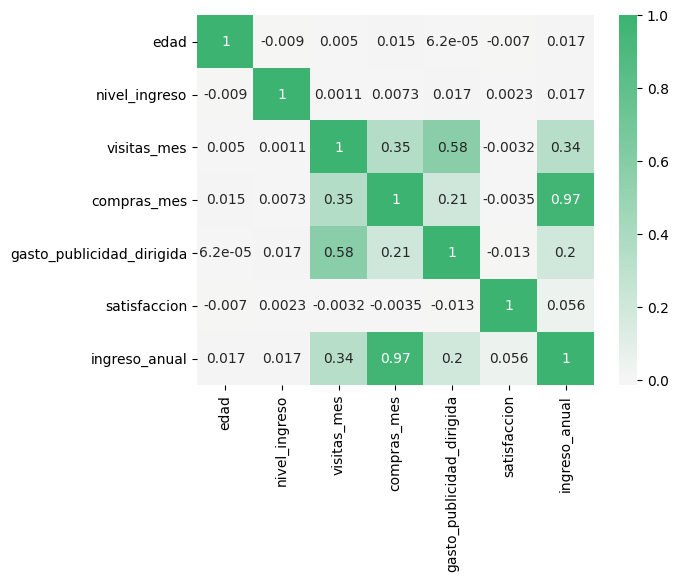

In [10]:
# Visualizar la matriz de correlación para identificar relaciones
df_corr = df[['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']].corr()
custom_cmap = LinearSegmentedColormap.from_list("TT_colors", ["peachpuff", "whitesmoke", "mediumseagreen"])
sns.heatmap(df_corr, annot=True, cmap = custom_cmap, center=0)
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
- Se observa que hay relaciones positivas como el  `ingreso_anual` y `compras_mes` de un valor de 0.97, como otros correlaciones positiva como lo son en `ingreso_anual` con `visitas_mes` del 0.34, pero al contrario una correlacion que no hay relación de las variables `edad` con `gasto_publicidad_dirigia` con un valor -6.2e-05 que esta mas cercano al 0.


Observaciones respecto a `ingreso_anual`  
- Presenta varias relaciones positivas con `visitas_mes`, `gasto_publicidad_dirigia` y `compras_mes` que es el comportamiento del cliente están más fuertemente asociados con el ingreso anual generado


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

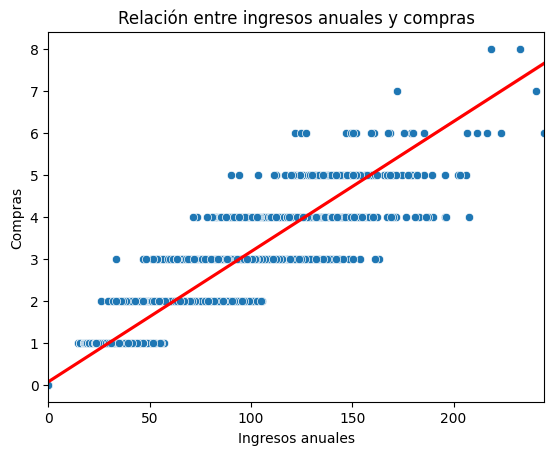

In [11]:
sns.scatterplot(data=df, x='ingreso_anual', y='compras_mes')
sns.regplot(data=df, x='ingreso_anual', y='compras_mes',
    scatter=False, color='red')
plt.title("Relación entre ingresos anuales y compras")
plt.xlabel("Ingresos anuales")
plt.ylabel("Compras")
plt.show()

### Scatterplot para pares clave

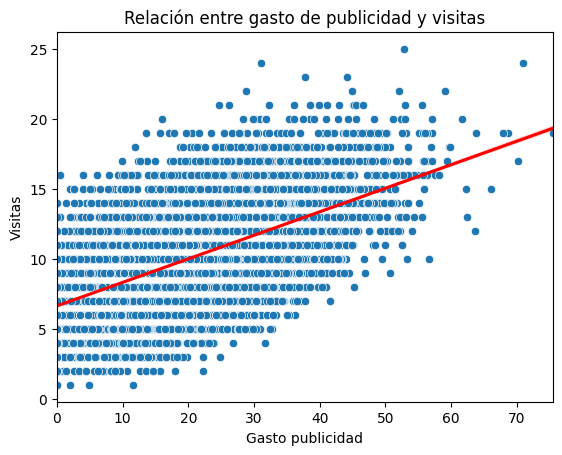

In [12]:
# Visualizar pares de variables con relaciones moderadas o fuertes
sns.scatterplot(data=df, x='gasto_publicidad_dirigida', y='visitas_mes')
sns.regplot(data=df, x='gasto_publicidad_dirigida', y='visitas_mes',
    scatter=False, color='red')
plt.title("Relación entre gasto de publicidad y visitas")
plt.xlabel("Gasto publicidad")
plt.ylabel("Visitas")
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.


Observaciones iniciales (Scatterplot)

**var1 vs var2**
- Dirección entre las variables 'ingreso_anual' y 'compras_mes' es una relación positvia, se grafico una linea para ver la tendecia que sube, tiene una despersión media.
- 

**var1 vs var3**
- Dirección entre las variables 'gasto_publicidad_dirigida' y 'visitas_mes' tiene una disperción moderada, tiene tendencia positiva por el aumento de la linea roja.
- 

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [13]:

# Calcular correlación entre variables relevantes
pearson_corr = df['ingreso_anual'].corr(df['compras_mes'], method='pearson')
print("Pearson:", pearson_corr)


Pearson: 0.9671485435708566


In [14]:
# Calcular correlación entre variables relevantes
spearman_corr = df['gasto_publicidad_dirigida'].corr(df['visitas_mes'], method='spearman')
print("Spearman:", spearman_corr)

Spearman: 0.5592673242622609


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

**var1 vs var2**
- Correlación entre `ingreso_anual` y `compras_mes`, es valor cercano a 1 quiere decir es es una correlación fuerte, tiene una dirección positiva, quiere decir cuando el ingreso anual sube, las compras mensuales tienden a subir.
- 

**var2 vs var3**
- Correlación entre `gasto_publicidad_dirigida` y `visitas_mes` es una correlación moderada ya que se observa un valor de 0.559, ya que es un valor positivo tiende a tener una dirección positiva.
- 

### Punto-biserial

In [15]:
# Calcular correlación entre variables relevantes
print(pointbiserialr(df['miembro_premium'], df['ingreso_anual']))
print(pointbiserialr(df['abandono'], df['ingreso_anual']))

SignificanceResult(statistic=0.0930994396198015, pvalue=3.0943076155242597e-30)
SignificanceResult(statistic=-0.002823934021617148, pvalue=0.7294691719078393)


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**var1 vs var2**
- Relación de `miembro_premium` e `ingreso_anual` tiene una correlacion debil debido a que tenemos un valor de 0.0931 cercano a 0  y al tener un pvalue tan bajo muy cercano a 0, entonces esta relacion es significativa ya que hay una asociación muy leve.

**var2 vs var3**
- Relación entre `abandono` e `ingreso_anual` tiene una correlación modernada al tener un statistic=-0.0028 y un pvalue=0.729 entonces esta relación es significativa.

### V de Cramér

In [16]:
# Función para calcular V de Cramér
def cramer_v(df, col1, col2):
    tabla = pd.crosstab(df[col1], df[col2])
    chi2, p_value, dof, expected = chi2_contingency(tabla)
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) -1)))
    return v

In [17]:
# Aplicar V de Cramér en variables relevantes
coef_cramer = cramer_v(df, "region", "tipo_dispositivo")
print("\nCorrelación entre: region y tipo dispositivo")
print(f"V de Cramér: {coef_cramer :.3f}")


Correlación entre: region y tipo dispositivo
V de Cramér: 0.012


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

Observaciones V de Cramér
]


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**: Completa los siguientes bloques.   
Si lo crees necesario, puedes agregar mas hallazgos.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### Hallazgo 1 — Las compras mensuales son el factor más fuertemente asociado con el ingreso anual

**Evidencia visual:** 
- Scatterplot de ingreso_anual vs compras_mes muestra una nube de puntos con tendencia clara ascendente
- Línea de regresión con pendiente positiva y pronunciada
**Evidencia numérica:** 
- Correlación de Pearson: 0.97 (valor muy cercano a 1)
- Relación casi lineal perfecta entre ambas variables.
- Valor p < 0,001 (estadísticamente significativo)
**Interpretación**  
Observamos una asociación muy fuerte entre el número de compras realizadas en un mes y el ingreso anual generado por el cliente. Esto significa que los clientes que compran más frecuentemente en el mes tienden a generar ingresos anuales más altos. Es la relación más robusta encontrada en el análisis.

**No podemos afirmar**  
- Que el aumento de compras causará mayor ingreso anual
- La dirección causal (¿más compras → más ingresos o más ingresos → más compras)
- Si existe una variable latente (ej: capacidad de gasto) que explique ambas

**Implicación de negocio**  
Este hallazgo sugiere que aumentar la frecuencia de compras por cliente es crítico para el ingresos. NovaRetail+ debe enfocarse en estrategias que incentivan múltiples compras mensuales (ej: programas de lealtad, descuentos por compra repetida, recordatorios personalizados) ya que existe una relación casi directa con ingresos.

### Hallazgo 2 — El gasto en publicidad dirigida se asocia moderadamente con visitas mensuales

**Evidencia visual:**  
- Scatterplot de gasto_publicidad_dirigida vs visitas_mes muestra dispersión moderada
- Línea de regresión con pendiente positiva pero con mayor variabilidad respecto a la línea
**Evidencia numérica:** 
- Correlación de Spearman: 0.559 (correlación moderada)
- Valor p < 0,001 (relación estadísticamente significativa)
- La variabilidad alrededor de la línea de tendencia es considerable.
**Interpretación**  
Existe una asociación positiva moderada entre el gasto en publicidad dirigida y el número de visitas mensuales. Clientes con mayor inversión publicitaria tienden a tener más visitas al sitio, pero esta relación es mucho menos determinística que la de compras con ingresos (hay mucha dispersión).

**No podemos afirmar**  
- Que invertir en publicidad causa más visitas
- Que toda inversión publicitaria resulta en visitas (algunos clientes no responden)
- El ROI específico de cada peso invertido en publicidad
- Si las visitas son de clientes nuevos o recurrentes

**Implicación de negocio**  
Si bien la publicidad dirigida se asocia con visitas, la relación no es perfecta. Sugiera que la eficacia de la publicidad varía según el cliente . NovaRetail+ podría:

- Segmentar clientes por respuesta a publicidad
- Optimizar el gasto publicitario por cliente (algunos no responden)
- Investigar qué características hacen que ciertos clientes sean más receptivos

### Hallazgo 3  — La membresía premium tiene una relación débil con el ingreso anual

**Evidencia visual:**
- Gráficos de distribución mostrarían dos grupos (miembros y no miembros) con ingresos similares
- Boxplot mostraría medias y dispersiones comparables

**Evidencia numérica:**
- Correlación Punto-biserial: 0.093 (muy cerca de 0, clasificación débil)
- Prima porcentaje de miembros: 13,9% (2.089 de 15.000)
- Valor p < 0,05 (relación estadísticamente significativa pero de magnitud muy pequeña)

**Interpretación (no causal):**
A pesar de ser estadísticamente significativa (debido al tamaño de muestra), la relación práctica es prácticamente inexistente . El hecho de ser miembro premium explica menos del 1% de la variación en ingresos anuales. Los clientes premium y no premium generan ingresos similares.

**No podemos afirmar:**
- Que la membresía premium causa mayor ingreso
- Que el programa premium es efectivo para aumentar los ingresos
- Qué valor agregado perciben los miembros premium
- Si los miembros premium compran más pero a menor precio

**Implicación de negocio:**
La membresía premium no es un predictor importante del ingreso . Esto sugiere:
- El modelo de prima podría no estar generando valor diferenciado
- NovaRetail+ debe revisar qué beneficios ofrece el premium y si son relevantes
- Estrategia alternativa: enfocarse en factores de comportamiento (frecuencia de compra) que SÍ generan ingresos, independientemente del estatus premium

## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**: Completa el siguiente bloque.   
Modifica según creas necesario.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### **Limitaciones**
- Correlación ≠ causalidad: Los hallazgos identifican relaciones (co-ocurrencias) pero no explican mecanismos causales
- Análisis transversal : Los datos corresponden a un período específico; no capturan dinámicas temporales (cambios en comportamiento a lo largo del tiempo)
- Variables omitidas : Pueden existir factores latentes (capacidad adquisitiva real, ciclo de vida del cliente, competencia) que expliquen las correlaciones
- Correlación de Pearson asume linealidad : Relaciones no lineales podrían no detectarse
- Tamaño de muestra grande amplifica significancia estadística : Correlaciones débiles (como premium=0.093) pueden ser "significativas" pero no prácticas
- Valores atípicos no analizados : Clientes con ingresos extraordinarios podrían distorsionar los resultados

### **Próximos pasos** 

Probar segmentación adicional
**Paso 1: Análisis de causalidad y hipótesis alternativas**
- Construir modelos predictivos (regresión) para entender qué variables explican mejor el ingreso
- Investigar si el abandono es predecible por otros factores (satisfacción, inactividad previa)
- Explorar si satisfacción actúa como variable mediadora entre visitas/compras e ingreso
  
**Paso 2: Segmentación y análisis por cohortes**
- Segmentar clientes por región (norte, sur, este, oeste) y examinar si las correlaciones varían
- Analizar diferencias por tipo de dispositivo (móvil, escritorio, tableta)
- Crear cohortes temporales para ver si el comportamiento cambia
  
**Paso 3: Análisis cualitativo y exploratorio**
- Encuestas a clientes que abandonan para entender motivaciones reales
- Entrevistas con clientes de alto/bajo ingreso para validar hipótesis
- Análisis de abandonos vs. retenidos en términos de satisfacción, interacciones previas
  
**Paso 4: Recomendaciones de negocio validadas**
- Diseñar test A/B para validar si incrementar publicidad realmente aumenta visitas
- Revisar arquitectura del programa premium y definir nuevos beneficios
- Crear un scoring de propensión a abandono basado en comportamiento para intervenciones tempranas